In [8]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

In [9]:
df = pd.read_csv('traffic1.csv')
df.head()

,Time,Date,Day of the week,CarCount,BikeCount,BusCount,TruckCount,Total,Traffic Situation
0,12:00:00 AM,10,Tuesday,31,0,4,4,39,low
1,12:15:00 AM,10,Tuesday,49,0,3,3,55,low
2,12:30:00 AM,10,Tuesday,46,0,3,6,55,low
3,12:45:00 AM,10,Tuesday,51,0,2,5,58,low
4,1:00:00 AM,10,Tuesday,57,6,15,16,94,normal


In [10]:
df.shape

(2976, 9)

In [11]:
df.isnull().sum()

Time                 0
Date                 0
Day of the week      0
CarCount             0
BikeCount            0
BusCount             0
TruckCount           0
Total                0
Traffic Situation    0
dtype: int64

In [12]:
df.duplicated().sum()

np.int64(0)

In [13]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2976 entries, 0 to 2975
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   Time               2976 non-null   str  
 1   Date               2976 non-null   int64
 2   Day of the week    2976 non-null   str  
 3   CarCount           2976 non-null   int64
 4   BikeCount          2976 non-null   int64
 5   BusCount           2976 non-null   int64
 6   TruckCount         2976 non-null   int64
 7   Total              2976 non-null   int64
 8   Traffic Situation  2976 non-null   str  
dtypes: int64(6), str(3)
memory usage: 275.4 KB


In [14]:
df['Traffic Situation'].value_counts()

Traffic Situation
normal    1669
heavy      682
high       321
low        304
Name: count, dtype: int64

In [15]:
df.describe()

,Date,CarCount,BikeCount,BusCount,TruckCount,Total
count,2976.000000,2976.000000,2976.000000,2976.000000,2976.000000,2976.000000
mean,16.000000,68.696573,14.917339,15.279570,15.324933,114.218414
std,8.945775,45.850693,12.847518,14.341986,10.603833,60.190627
min,1.000000,6.000000,0.000000,0.000000,0.000000,21.000000
25%,8.000000,19.000000,5.000000,1.000000,6.000000,55.000000
50%,16.000000,64.000000,12.000000,12.000000,14.000000,109.000000
75%,24.000000,107.000000,22.000000,25.000000,23.000000,164.000000
max,31.000000,180.000000,70.000000,50.000000,40.000000,279.000000


EDA

<Axes: xlabel='Traffic Situation', ylabel='count'>

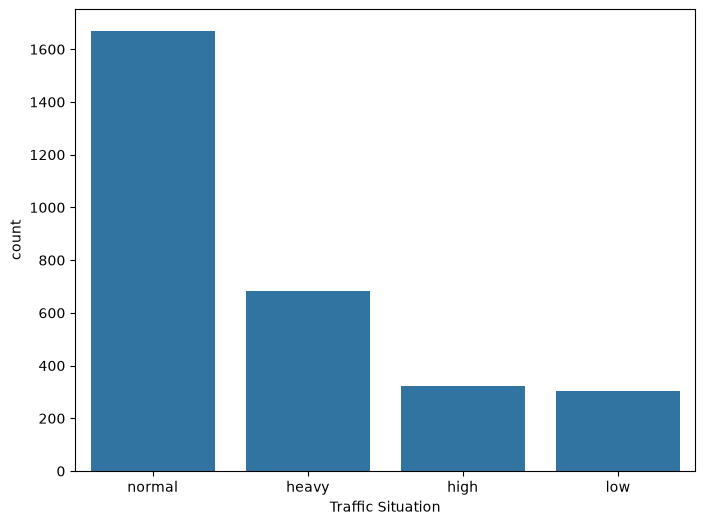

In [19]:
plt.figure(figsize=(8,6))
sns.countplot(
    data = df,
    x = 'Traffic Situation',
    order = df['Traffic Situation'].value_counts().index
)

In [20]:
vehicle_sum = (
    df['CarCount'] +
    df['BikeCount'] +
    df['BusCount'] +
    df['TruckCount']
)

print("Total matches vehicle sum:", (df['Total'] == vehicle_sum).all())

print("\nSample comparison:")
display(pd.DataFrame({
    'Actual Total': df['Total'].head(10),
    'Calculated Total': vehicle_sum.head(10)
}))

Total matches vehicle sum: True

Sample comparison:


,Actual Total,Calculated Total
0,39,39
1,55,55
2,55,55
3,58,58
4,94,94
5,53,53
6,42,42
7,55,55
8,67,67
9,45,45


In [21]:
print("All rows match:", (df['Total'] == vehicle_sum).all())

All rows match: True


In [24]:
print("Unique Time values:")
print(df['Time'].unique()[:20])

print("\nUnique Dates:")
print(sorted(df['Date'].unique()))

print("\nDays of the Week:")
print(df['Day of the week'].value_counts())

Unique Time values:
<ArrowStringArray>
['12:00:00 AM', '12:15:00 AM', '12:30:00 AM', '12:45:00 AM',  '1:00:00 AM',
  '1:15:00 AM',  '1:30:00 AM',  '1:45:00 AM',  '2:00:00 AM',  '2:15:00 AM',
  '2:30:00 AM',  '2:45:00 AM',  '3:00:00 AM',  '3:15:00 AM',  '3:30:00 AM',
  '3:45:00 AM',  '4:00:00 AM',  '4:15:00 AM',  '4:30:00 AM',  '4:45:00 AM']
Length: 20, dtype: str

Unique Dates:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24), np.int64(25), np.int64(26), np.int64(27), np.int64(28), np.int64(29), np.int64(30), np.int64(31)]

Days of the Week:
Day of the week
Tuesday      480
Wednesday    480
Thursday     480
Friday       384
Saturday     384
Sunday       384
Monday       384
Name: count, dtype: int64


In [25]:
# Convert Time into datetime format
df['Time'] = pd.to_datetime(
    df['Time'],
    format='%I:%M:%S %p'
)

# Extract hour and minute
df['Hour'] = df['Time'].dt.hour
df['Minute'] = df['Time'].dt.minute

display(df[['Time', 'Hour', 'Minute']].head(10))

,Time,Hour,Minute
0,1900-01-01 00:00:00,0,0
1,1900-01-01 00:15:00,0,15
2,1900-01-01 00:30:00,0,30
3,1900-01-01 00:45:00,0,45
4,1900-01-01 01:00:00,1,0
5,1900-01-01 01:15:00,1,15
6,1900-01-01 01:30:00,1,30
7,1900-01-01 01:45:00,1,45
8,1900-01-01 02:00:00,2,0
9,1900-01-01 02:15:00,2,15


In [26]:
df.head()

,Time,Date,Day of the week,CarCount,BikeCount,BusCount,TruckCount,Total,Traffic Situation,Hour,Minute
0,1900-01-01 00:00:00,10,Tuesday,31,0,4,4,39,low,0,0
1,1900-01-01 00:15:00,10,Tuesday,49,0,3,3,55,low,0,15
2,1900-01-01 00:30:00,10,Tuesday,46,0,3,6,55,low,0,30
3,1900-01-01 00:45:00,10,Tuesday,51,0,2,5,58,low,0,45
4,1900-01-01 01:00:00,10,Tuesday,57,6,15,16,94,normal,1,0


One hot encoding

In [27]:
from sklearn.preprocessing import OneHotEncoder

In [28]:
encoder = OneHotEncoder(sparse_output=False)

In [29]:
days_encoded = encoder.fit_transform(df[["Day of the week"]])

In [32]:
day_df = pd.DataFrame(
    days_encoded,
    columns=encoder.get_feature_names_out(['Day of the week'])
)


In [33]:
day_df.head()

,Day of the week_Friday,Day of the week_Monday,Day of the week_Saturday,Day of the week_Sunday,Day of the week_Thursday,Day of the week_Tuesday,Day of the week_Wednesday
0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,0.0,0.0,0.0,0.0,0.0,1.0,0.0


In [34]:
df = pd.concat([df, day_df], axis =1)

In [35]:
df.drop('Day of the week', axis = 1, inplace= True)

In [37]:
display(df.head())

,Time,Date,CarCount,BikeCount,BusCount,TruckCount,Total,Traffic Situation,Hour,Minute,Day of the week_Friday,Day of the week_Monday,Day of the week_Saturday,Day of the week_Sunday,Day of the week_Thursday,Day of the week_Tuesday,Day of the week_Wednesday
0,1900-01-01 00:00:00,10,31,0,4,4,39,low,0,0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,1900-01-01 00:15:00,10,49,0,3,3,55,low,0,15,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2,1900-01-01 00:30:00,10,46,0,3,6,55,low,0,30,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3,1900-01-01 00:45:00,10,51,0,2,5,58,low,0,45,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,1900-01-01 01:00:00,10,57,6,15,16,94,normal,1,0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
